# 04 · Supervised PC-CNN with centered Equilibrium Propagation: MNIST classification

- Kerjan, Høier & Scellier (2026), arXiv:2606.03584.


## 1. Configuration and reproducible data split

In [1]:
import copy, random, time, math
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
from archive.utils import get_device
DEVICE = get_device()
DATA_ROOT = Path('data/mnist')
PROFILE = 'verification'  # 'verification' or 'previous_widths'
IMAGE_SIZE = 32 if PROFILE == 'verification' else 64
CHANNELS = (16, 32, 64, 128) if PROFILE == 'verification' else (64, 128, 256, 512)
BATCH_SIZE = 32 if PROFILE == 'verification' else 8
TRAIN_IMAGES_PER_CLASS = 167
VAL_IMAGES_PER_CLASS = 17
NUM_CLASSES = 10
EPOCHS = 100
INFERENCE_STEPS = 5
NUDGE_STEPS = 20
BETA = 0.05
NUDGE_COST = 'ce'  # paper reports both MSE and CE; MSE is default for MNIST verification
LR_WEIGHT = 0.02
GLOBAL_UPDATE_NORM_LIMIT = 5.0  # one global limit for the complete centered update, not per-bias relative clipping
WEIGHT_DECAY = 0.0
EVAL_EVERY = 1
CKPT = f'checkpoints_04_pccnn_centered_ep_{PROFILE}_best.pth'
print('Device:', DEVICE, '| Profile:', PROFILE, '| Input:', IMAGE_SIZE, '| Channels:', CHANNELS)
print('Beta:', BETA, '| Nudge steps:', NUDGE_STEPS, '| Nudge cost:', NUDGE_COST, '| Weight LR:', LR_WEIGHT, '| Inference steps:', INFERENCE_STEPS)


Device: mps | Profile: verification | Input: 32 | Channels: (16, 32, 64, 128)
Beta: 0.05 | Nudge steps: 20 | Nudge cost: ce | Weight LR: 0.02 | Inference steps: 5


In [2]:
def balanced_mnist_split(dataset, train_per_class, val_per_class, seed=SEED):
    labels = torch.as_tensor(dataset.targets)
    generator = torch.Generator().manual_seed(seed)
    train_idx, val_idx = [], []
    for c in range(NUM_CLASSES):
        idx = torch.where(labels == c)[0]
        perm = idx[torch.randperm(len(idx), generator=generator)]
        assert len(perm) >= train_per_class + val_per_class
        train_idx.extend(perm[:train_per_class].tolist())
        val_idx.extend(perm[train_per_class:train_per_class + val_per_class].tolist())
    assert set(train_idx).isdisjoint(val_idx)
    return Subset(dataset, train_idx), Subset(dataset, val_idx)

tf = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE), interpolation=transforms.InterpolationMode.BILINEAR), transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
full_train = datasets.MNIST(root=DATA_ROOT, train=True, download=True, transform=tf)
test_ds = datasets.MNIST(root=DATA_ROOT, train=False, download=True, transform=tf)
train_ds, val_ds = balanced_mnist_split(full_train, TRAIN_IMAGES_PER_CLASS, VAL_IMAGES_PER_CLASS)
kwargs = dict(batch_size=BATCH_SIZE, num_workers=0, pin_memory=False)
train_loader = DataLoader(train_ds, shuffle=True, generator=torch.Generator().manual_seed(SEED), **kwargs)
train_eval_loader = DataLoader(train_ds, shuffle=False, **kwargs)
val_loader = DataLoader(val_ds, shuffle=False, **kwargs)
test_loader = DataLoader(test_ds, shuffle=False, **kwargs)
print('Train:', len(train_ds), '| Validation:', len(val_ds), '| Untouched MNIST test:', len(test_ds))


Train: 1670 | Validation: 170 | Untouched MNIST test: 10000


In [3]:
class CenteredEPPCNN(nn.Module):
    def __init__(self, channels=CHANNELS, num_classes=NUM_CLASSES):
        super().__init__()
        widths = [1] + list(channels)
        self.strides = (2, 2, 2, 1)
        self.num_classes = num_classes
        self.nudge_cost = NUDGE_COST
        self.bottom_weights = nn.ParameterList([nn.Parameter(torch.empty(widths[i+1], widths[i], 3, 3), requires_grad=False) for i in range(4)])
        self.bottom_biases = nn.ParameterList([nn.Parameter(torch.zeros(widths[i+1]), requires_grad=False) for i in range(4)])
        self.W_cls = nn.Parameter(torch.empty(num_classes, channels[-1]), requires_grad=False)
        self.b_cls = nn.Parameter(torch.zeros(num_classes), requires_grad=False)
        for W in self.bottom_weights:
            nn.init.kaiming_normal_(W, mode='fan_out', nonlinearity='relu')
            W.mul_(0.75)
        nn.init.normal_(self.W_cls, mean=0.0, std=0.04)

    def conv_pre(self, index, source):
        return F.conv2d(source, self.bottom_weights[index], self.bottom_biases[index], stride=self.strides[index], padding=1)

    def classifier_prediction(self, z4):
        return F.linear(z4.mean((2,3)), self.W_cls, self.b_cls)

    def classification_cost(self, logits, y):
        if self.nudge_cost == 'mse':
            return 0.5 * (logits - F.one_hot(y, self.num_classes).float()).square().sum(1).mean()
        if self.nudge_cost == 'ce':
            return F.cross_entropy(logits, y)
        raise ValueError(f'Unknown nudging cost: {self.nudge_cost}')

    def classification_cost_state_gradient(self, logits, y):
        if self.nudge_cost == 'mse': return logits - F.one_hot(y, self.num_classes).float()
        if self.nudge_cost == 'ce': return logits.softmax(1) - F.one_hot(y, self.num_classes).float()
        raise ValueError(f'Unknown nudging cost: {self.nudge_cost}')

    @torch.no_grad()
    def feedforward_states(self, x):
        states = []
        for i in range(4):
            source = x if i == 0 else states[-1]
            states.append(self.conv_pre(i, source).relu())
        states.append(self.classifier_prediction(states[-1]))
        return states

    @torch.no_grad()
    def predict(self, x):
        return self.feedforward_states(x)[-1]

    @torch.no_grad()
    def local_predictions_and_errors(self, x, states):
        predictions, preacts = [], []
        for i in range(4):
            source = x if i == 0 else states[i-1]
            preact = self.conv_pre(i, source)
            preacts.append(preact)
            predictions.append(preact.relu())
        predictions.append(self.classifier_prediction(states[3]))
        errors = [s-p for s,p in zip(states,predictions)]
        return predictions, preacts, errors

    @torch.no_grad()
    def bottom_up_prediction_error(self, x, states):
        return self.local_predictions_and_errors(x, states)[2]

    @torch.no_grad()
    def top_down_error_feedback(self, x, states, index):
        # Return J_(index+1)^T epsilon_(index+1), with index=0..3.
        if index == 3:
            epsilon_out = states[4] - self.classifier_prediction(states[3])
            h, w = states[3].shape[-2:]
            return (epsilon_out @ self.W_cls).reshape(-1, states[3].shape[1], 1, 1).expand_as(states[3]) / (h*w)
        next_a = self.conv_pre(index+1, states[index])
        next_error = states[index+1] - next_a.relu()
        delta = next_error * (next_a > 0).to(next_a.dtype)
        output_padding = self.strides[index+1] - 1
        return F.conv_transpose2d(delta, self.bottom_weights[index+1], stride=self.strides[index+1], padding=1, output_padding=output_padding)

    @torch.no_grad()
    def energy_parts(self, x, states, y=None, beta=0.0):
        errors = self.bottom_up_prediction_error(x, states)
        per_level = [0.5 * e.square().flatten(1).sum(1).mean() for e in errors]
        cost = states[-1].new_zeros(()) if y is None else self.classification_cost(states[-1], y)
        return per_level, cost, sum(per_level) + beta*cost

    @torch.no_grad()
    def manual_state_gradients(self, x, states, y=None, beta=0.0):
        _, _, errors = self.local_predictions_and_errors(x, states)
        grads = [errors[i] - self.top_down_error_feedback(x, states, i) for i in range(4)]
        output = errors[-1]
        if y is not None and beta != 0:
            output = output + beta*self.classification_cost_state_gradient(states[-1], y)
        grads.append(output)
        return grads

    @torch.no_grad()
    def nudged_states(self, x, y, beta, steps=NUDGE_STEPS):
        # A free equilibrium is obtained by feedforward; do not iterate the free phase.
        states = [s.clone() for s in self.feedforward_states(x)]
        if beta == 0: return states
        for _ in range(steps):
            # Asynchronous even/odd sweeps, most-top-down group first to accelerate signal travel.
            for group in ((4, 2, 0), (3, 1)):
                for i in group:
                    if i == 4:
                        pred = self.classifier_prediction(states[3])
                        class_grad = self.classification_cost_state_gradient(states[4], y)
                        states[4] = pred - beta*class_grad
                    else:
                        source = x if i == 0 else states[i-1]
                        preact = self.conv_pre(i, source)
                        feedback = self.top_down_error_feedback(x, states, i)
                        # mod-PGD at alpha=1, based on preactivation (not ReLU(preactivation)).
                        states[i] = (preact + feedback).relu()
            if not all(torch.isfinite(s).all().item() for s in states): raise FloatingPointError('Nonfinite nudged states: lower LR, beta or inspect the model.')
        return states

    @torch.no_grad()
    def local_negative_weight_gradient(self, x, states):
        # Returns -dE/dtheta at fixed states, as LOCAL presynaptic activity * postsynaptic prediction error.
        _, preacts, errors = self.local_predictions_and_errors(x, states)
        B = x.size(0)
        signal = {}
        for i, W in enumerate(self.bottom_weights):
            source = x if i == 0 else states[i-1]
            delta = errors[i] * (preacts[i] > 0).to(errors[i].dtype)
            signal[f'bottom_weights.{i}'] = torch.nn.grad.conv2d_weight(source, W.shape, delta, stride=self.strides[i], padding=1) / B
            signal[f'bottom_biases.{i}'] = delta.sum((0,2,3)) / B
        pooled = states[3].mean((2,3))
        signal['W_cls'] = errors[4].T @ pooled / B
        signal['b_cls'] = errors[4].mean(0)
        return signal

    @torch.no_grad()
    def centered_updates(self, x, y, beta=BETA, steps=NUDGE_STEPS):
        pos = self.nudged_states(x, y, +beta, steps)
        neg = self.nudged_states(x, y, -beta, steps)
        gp = self.local_negative_weight_gradient(x, pos)
        gn = self.local_negative_weight_gradient(x, neg)
        updates = {k:(gp[k] - gn[k])/(2*beta) for k in gp}
        return updates, pos, neg

    @torch.no_grad()
    def train_step_ep(self, x, y, beta=BETA, steps=NUDGE_STEPS, lr=LR_WEIGHT, norm_limit=GLOBAL_UPDATE_NORM_LIMIT, weight_decay=WEIGHT_DECAY):
        updates, pos, neg = self.centered_updates(x, y, beta, steps)
        parameters = dict(self.named_parameters())
        if weight_decay:
            updates = {name: update - weight_decay*parameters[name] for name,update in updates.items()}
        global_norm = math.sqrt(sum(float(v.square().sum()) for v in updates.values()))
        if not math.isfinite(global_norm): raise FloatingPointError('Nonfinite EP parameter update')
        clip_scale = min(1.0, norm_limit/max(global_norm, 1e-12)) if norm_limit is not None else 1.0
        for name, delta in updates.items():
            parameters[name].add_(lr*clip_scale*delta)
        if not all(torch.isfinite(p).all().item() for p in self.parameters()): raise FloatingPointError('Nonfinite PCN weights after EP update')
        return {'norm':global_norm,'clipped':clip_scale<1.0,'layer_update_norms':[float(updates[f'bottom_weights.{i}'].norm()) for i in range(4)],'pos':pos,'neg':neg}


## 5. Train the PC-CNN with manual centered EP


In [6]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); correct=0; total=0; ce_sum=0.0
    for x,y in loader:
        x=x.to(DEVICE);y=y.to(DEVICE)
        logits=model.predict(x)
        correct += (logits.argmax(1)==y).sum().item()
        total += y.numel()
        ce_sum += F.cross_entropy(logits,y,reduction='sum').item()
    return 100*correct/max(total,1), ce_sum/max(total,1)

# Reinitialize AFTER diagnostics so the experimental model is truly fresh.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
model = CenteredEPPCNN().to(DEVICE)
history=[]; best_val=-1.0; best_epoch=0; best_weights=None
for epoch in range(1,EPOCHS+1):
    model.train(); start=time.time(); count_clipped=0; update_norms=[]
    for x,y in tqdm(train_loader,desc=f'Epoch {epoch}',leave=False):
        x=x.to(DEVICE);y=y.to(DEVICE)
        stats=model.train_step_ep(x,y)
        count_clipped += int(stats['clipped'])
        update_norms.append(stats['layer_update_norms'])
    tr,tl=evaluate(model,train_eval_loader)
    va,vl=evaluate(model,val_loader)
    mean_norms = np.mean(update_norms,axis=0).tolist()
    record=dict(epoch=epoch,train_accuracy=tr,val_accuracy=va,train_ce=tl,val_ce=vl,clipped_batches=count_clipped,mean_conv_update_norms=mean_norms)
    history.append(record)
    if va>best_val:
        best_val,best_epoch=va,epoch
        best_weights=copy.deepcopy(model.state_dict())
        torch.save({'model_state_dict':best_weights,'best_epoch':best_epoch,'best_val_accuracy':best_val,'history':history,'config':dict(profile=PROFILE,image_size=IMAGE_SIZE,channels=CHANNELS,beta=BETA,nudge_steps=NUDGE_STEPS,nudge_cost=NUDGE_COST,lr_weight=LR_WEIGHT,train_per_class=TRAIN_IMAGES_PER_CLASS,val_per_class=VAL_IMAGES_PER_CLASS,seed=SEED)},CKPT)
    print(f'Epoch {epoch:02d} | Train {tr:.2f}% | Val {va:.2f}% | Val CE {vl:.4f} | Clipped batches {count_clipped} | Best {best_val:.2f}% (epoch {best_epoch}) | {time.time()-start:.0f}s')
    print('    Mean centered Conv update norms L1-4:',[round(v,5) for v in mean_norms])
model.load_state_dict(best_weights)
print(f'Restored epoch {best_epoch}; best validation accuracy {best_val:.2f}%')


Epoch 1:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 01 | Train 10.00% | Val 10.00% | Val CE 2.3026 | Clipped batches 0 | Best 10.00% (epoch 1) | 6s
    Mean centered Conv update norms L1-4: [0.00734, 0.00898, 0.01146, 0.02198]


Epoch 2:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 02 | Train 10.00% | Val 9.41% | Val CE 2.3025 | Clipped batches 0 | Best 10.00% (epoch 1) | 5s
    Mean centered Conv update norms L1-4: [0.00706, 0.00892, 0.01171, 0.02273]


Epoch 3:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 03 | Train 10.24% | Val 10.00% | Val CE 2.3025 | Clipped batches 0 | Best 10.00% (epoch 1) | 5s
    Mean centered Conv update norms L1-4: [0.00725, 0.00891, 0.01171, 0.02242]


... (190 outputs left out)

Epoch 99:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 99 | Train 87.43% | Val 82.94% | Val CE 0.4570 | Clipped batches 13 | Best 82.94% (epoch 95) | 6s
    Mean centered Conv update norms L1-4: [0.13094, 0.47127, 1.54568, 2.81118]


Epoch 100:   0%|          | 0/53 [00:00<?, ?it/s]

Epoch 100 | Train 84.61% | Val 81.76% | Val CE 0.5808 | Clipped batches 8 | Best 82.94% (epoch 95) | 6s
    Mean centered Conv update norms L1-4: [0.12271, 0.4507, 1.53321, 2.80931]
Restored epoch 95; best validation accuracy 82.94%


## 6. Training/validation accuracy and loss curves (every recorded epoch)

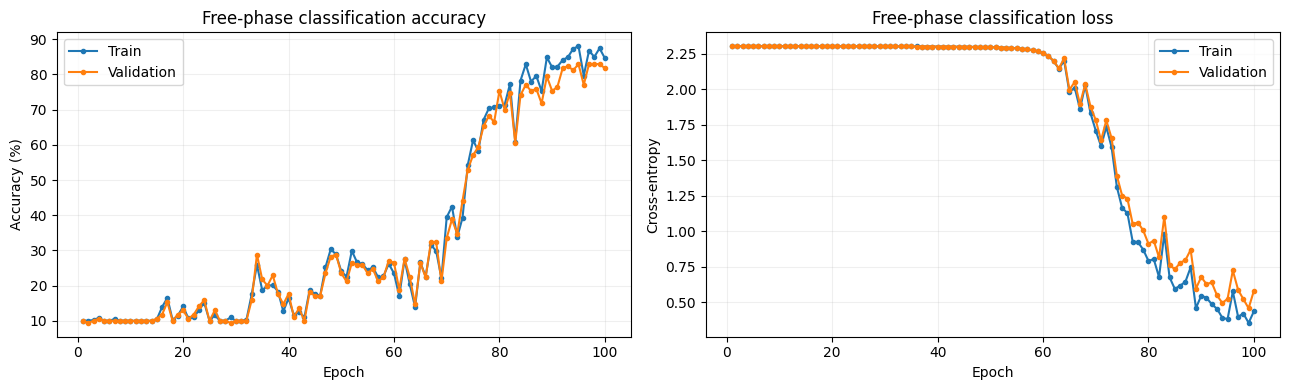

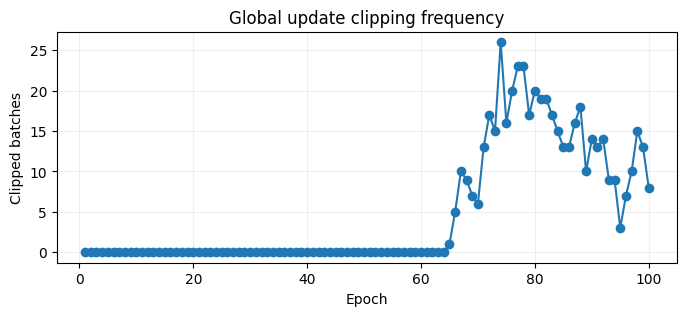

In [7]:
epochs=[h['epoch'] for h in history]
fig,axs=plt.subplots(1,2,figsize=(13,4))
axs[0].plot(epochs,[h['train_accuracy'] for h in history],marker='.',label='Train')
axs[0].plot(epochs,[h['val_accuracy'] for h in history],marker='.',label='Validation')
axs[0].set(xlabel='Epoch',ylabel='Accuracy (%)',title='Free-phase classification accuracy')
axs[0].legend();axs[0].grid(alpha=.2)
axs[1].plot(epochs,[h['train_ce'] for h in history],marker='.',label='Train')
axs[1].plot(epochs,[h['val_ce'] for h in history],marker='.',label='Validation')
axs[1].set(xlabel='Epoch',ylabel='Cross-entropy',title='Free-phase classification loss')
axs[1].legend();axs[1].grid(alpha=.2)
plt.tight_layout();plt.show()

plt.figure(figsize=(8,3));plt.plot(epochs,[h['clipped_batches'] for h in history],marker='o');plt.xlabel('Epoch');plt.ylabel('Clipped batches');plt.title('Global update clipping frequency');plt.grid(alpha=.2);plt.show()


## 7. Post-training signal diagnostic (best checkpoint)

In [8]:
@torch.no_grad()
def ep_learning_audit(model, loader, sample_count=4):
    x,y=next(iter(loader)); x=x[:sample_count].to(DEVICE);y=y[:sample_count].to(DEVICE)
    free=model.feedforward_states(x)
    plus=model.nudged_states(x,y,+BETA,NUDGE_STEPS)
    minus=model.nudged_states(x,y,-BETA,NUDGE_STEPS)
    for name,s in [('free',free),('positive nudge',plus),('negative nudge',minus)]:
        losses,ce,total=model.energy_parts(x,s,y,+BETA if name=='positive nudge' else -BETA if name=='negative nudge' else 0.0)
        print(name,'| prediction loss by layer:',[round(float(v),6) for v in losses],'| nudging cost:',round(float(ce),6),'| total F:',round(float(total),6))
    print('State response to positive vs negative nudging:')
    for i,(p,m) in enumerate(zip(plus,minus),1):
        print(f' Level {i}: RMS separation={float((p-m).square().mean().sqrt()):.8f}')
    updates,_,_=model.centered_updates(x,y,BETA,NUDGE_STEPS)
    print('Centered local update norms:',{f'conv{i+1}':round(float(updates[f"bottom_weights.{i}"].norm()),7) for i in range(4)})

ep_learning_audit(model,val_loader)


free | prediction loss by layer: [0.0, 0.0, 0.0, 0.0, 0.0] | nudging cost: 0.102408 | total F: 0.0
positive nudge | prediction loss by layer: [1.1e-05, 3e-06, 1e-06, 1e-06, 4.1e-05] | nudging cost: 0.100086 | total F: 0.005062
negative nudge | prediction loss by layer: [1.2e-05, 3e-06, 2e-06, 2e-06, 4.5e-05] | nudging cost: 0.1049 | total F: -0.005182
State response to positive vs negative nudging:
 Level 1: RMS separation=0.00015084
 Level 2: RMS separation=0.00063704
 Level 3: RMS separation=0.00174719
 Level 4: RMS separation=0.00191666
 Level 5: RMS separation=0.00847545
Centered local update norms: {'conv1': 0.163725, 'conv2': 0.5547079, 'conv3': 1.5646011, 'conv4': 3.6688395}


In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for x, y in val_loader:
        pred = model.predict(x.to(DEVICE)).argmax(dim=1)
        y_true.extend(y.cpu().tolist())
        y_pred.extend(pred.cpu().tolist())

classes = list(range(10))
cm = confusion_matrix(y_true, y_pred, labels=classes)

print("CONFUSION MATRIX")
display(pd.DataFrame(cm, index=classes, columns=classes))

print("\nCLASS-WISE METRICS")
report = classification_report(y_true, y_pred, labels=classes, output_dict=True, zero_division=0)
metrics = pd.DataFrame(report).T.iloc[:10][["precision", "recall", "f1-score", "support"]]
metrics["accuracy (%)"] = np.divide(cm.diagonal(), cm.sum(axis=1), out=np.zeros(10, dtype=float),
                                    where=cm.sum(axis=1) > 0) * 100
display(metrics.round(3))

print(f"Overall Accuracy: {100 * np.trace(cm) / cm.sum():.2f}%")

CONFUSION MATRIX


,0,1,2,3,4,5,6,7,8,9
0,16,0,0,0,0,0,1,0,0,0
1,0,17,0,0,0,0,0,0,0,0
2,1,0,11,0,0,0,3,0,2,0
3,0,0,0,12,0,0,0,1,4,0
4,0,0,0,0,13,0,2,0,1,1
5,2,0,0,0,0,11,1,0,3,0
6,0,0,0,0,0,0,17,0,0,0
7,0,0,1,1,0,1,0,14,0,0
8,0,0,0,0,0,0,0,0,17,0
9,1,0,0,1,0,0,0,2,0,13



CLASS-WISE METRICS


,precision,recall,f1-score,support,accuracy (%)
0,0.800,0.941,0.865,17.0,94.118
1,1.000,1.000,1.000,17.0,100.000
2,0.917,0.647,0.759,17.0,64.706
3,0.857,0.706,0.774,17.0,70.588
4,1.000,0.765,0.867,17.0,76.471
5,0.917,0.647,0.759,17.0,64.706
6,0.708,1.000,0.829,17.0,100.000
7,0.824,0.824,0.824,17.0,82.353
8,0.630,1.000,0.773,17.0,100.000
9,0.929,0.765,0.839,17.0,76.471


Overall Accuracy: 82.94%
